# Conditional Transformer CVAE with a Normalizing-Flow Posterior for QM9 SMILES

This notebook retains the Transformer encoder/decoder and dynamic condition gates, and replaces the diagonal-Gaussian posterior used directly by the decoder with a **conditional RealNVP posterior flow**. The prior in the final latent space remains standard normal, so generation samples directly from `N(0, I)`.

The notebook follows the existing Model D organization and trains on the complete supplied CSV, as in the source notebook. It does not add a train/validation/test split.


## 1. Install dependencies

Run this cell in the notebook environment. DeepChem/RDKit installation may depend on your Python version and operating system; if installation fails, use a fresh compatible environment or follow the installation instructions for those packages.


In [1]:
%pip install deepchem rdkit pandas numpy torch


Note: you may need to restart the kernel to use updated packages.


## 2. Define the QM9 preparation function

This code calls DeepChem's built-in QM9 loader, selects only `u298`, `h298`, and `g298`, converts the molecule structures to canonical SMILES with RDKit, removes failed/missing rows and duplicate canonical SMILES, and writes a CSV with exactly four columns: `smiles`, `U`, `H`, and `G`.


In [2]:
#!/usr/bin/env python
"""
Prepare a clean QM9 CSV with only canonical SMILES and the U/H/G properties.

DeepChem's QM9 task names are:
    u298 = internal energy at 298.15 K
    h298 = enthalpy at 298.15 K
    g298 = free energy at 298.15 K

The output CSV uses the column names: smiles, U, H, G.
QM9 energy values are kept in their original Hartree units.

Install (in a compatible environment):
    pip install deepchem rdkit pandas numpy

Run:
    python prepare_qm9_uhg.py --output qm9_smiles_U_H_G.csv

DeepChem may download and cache the source QM9 data on the first run.
"""

import argparse
import os
import sys

import numpy as np
import pandas as pd


REQUIRED_TASKS = ("u298", "h298", "g298")


def molecule_to_smiles(value):
    """Convert a DeepChem/RDKit molecule to canonical SMILES."""
    from rdkit import Chem

    if value is None:
        return None

    if isinstance(value, (str, np.str_)):
        mol = Chem.MolFromSmiles(str(value))
    else:
        mol = value

    if mol is None:
        return None

    try:
        mol = Chem.RemoveHs(mol)
        return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    except Exception:
        return None


def prepare_qm9(output_path, data_dir, save_dir, reload_cache=True):
    import deepchem as dc

    # DummyFeaturizer preserves the RDKit molecules in X instead of converting
    # them into numeric descriptors. splitter=None returns the complete dataset.
    tasks, datasets, _ = dc.molnet.load_qm9(
        featurizer=dc.feat.RawFeaturizer(smiles=True),
        splitter=None,
        transformers=[],
        reload=reload_cache,
        data_dir=data_dir,
        save_dir=save_dir,
    )

    if not datasets:
        raise RuntimeError("DeepChem returned no QM9 dataset.")
    dataset = datasets[0]

    task_lookup = {str(task).lower(): idx for idx, task in enumerate(tasks)}
    missing = [task for task in REQUIRED_TASKS if task not in task_lookup]
    if missing:
        raise RuntimeError(
            f"DeepChem's QM9 tasks do not contain {missing}. Found: {list(tasks)}"
        )

    target_indices = [task_lookup[task] for task in REQUIRED_TASKS]
    y = np.asarray(dataset.y)
    if y.ndim != 2 or y.shape[1] <= max(target_indices):
        raise RuntimeError(
            f"Unexpected target-array shape {y.shape}; expected one column per QM9 task."
        )

    target_values = y[:, target_indices]
    molecules = dataset.X
    if len(molecules) != len(target_values):
        raise RuntimeError(
            f"SMILES source and target row counts differ: "
            f"{len(molecules)} vs {len(target_values)}"
        )

    smiles_values = [molecule_to_smiles(m) for m in molecules]
    frame = pd.DataFrame({
        "smiles": smiles_values,
        "U": target_values[:, 0],  # u298
        "H": target_values[:, 1],  # h298
        "G": target_values[:, 2],  # g298
    })

    # Remove failed molecule conversions and missing/non-finite labels.
    frame = frame.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    frame = frame[frame["smiles"].astype(str).str.len() > 0].reset_index(drop=True)

    # Keep only one row per canonical SMILES, retaining the first occurrence.
    before_dedup = len(frame)
    frame = frame.drop_duplicates(subset=["smiles"], keep="first").reset_index(drop=True)

    output_dir = os.path.dirname(os.path.abspath(output_path))
    os.makedirs(output_dir, exist_ok=True)
    frame.to_csv(output_path, index=False)

    print("QM9 export complete.")
    print(f"DeepChem task names selected: {REQUIRED_TASKS}")
    print(f"Output file: {os.path.abspath(output_path)}")
    print(f"Rows after cleaning: {len(frame):,}")
    print(f"Duplicate canonical SMILES removed: {before_dedup - len(frame):,}")
    print("Columns:", ", ".join(frame.columns))
    print("Energy units: Hartree (U=u298, H=h298, G=g298)")
    print("\nFirst five rows:")
    print(frame.head().to_string(index=False))
    return frame

## 3. Download/load QM9 and export the selected data

Change `OUTPUT_CSV`, `DATA_DIR`, or `SAVE_DIR` to use different paths. The dataset loader uses `splitter=None` so that the extracted dataframe contains the complete dataset returned by DeepChem, not only one split.


In [3]:
OUTPUT_CSV = "qm9_smiles_U_H_G.csv"
DATA_DIR = "./deepchem_data"
SAVE_DIR = "./deepchem_cache"

qm9_df = prepare_qm9(
    output_path=OUTPUT_CSV,
    data_dir=DATA_DIR,
    save_dir=SAVE_DIR,
    reload_cache=True,
)

print("\nDataset shape:", qm9_df.shape)
display(qm9_df.head())


C:\Users\ch19095\miniconda3\envs\myproject\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
QM9 export complete.
DeepChem task names selected: ('u298', 'h298', 'g298')
Output file: C:\Users\ch19095\Documents\qm9_smiles_U_H_G.csv
Rows after cleaning: 131,698
Duplicate canonical SMILES removed: 272
Columns: smiles, U, H, G
Energy units: Hartree (U=u298, H=h298, G=g298)

First five rows:
smiles          U          H          G
     C -40.476062 -40.475117 -40.498597
     N -56.523026 -56.522082 -56.544961
     O -76.401867 -76.400922 -76.422349
   C#C -77.305527 -77.304583 -77.327429
   C#N -93.409370 -93.408425 -93.431246

Dataset shape: (131698, 4)


,smiles,U,H,G
0,C,-40.476062,-40.475117,-40.498597
1,N,-56.523026,-56.522082,-56.544961
2,O,-76.401867,-76.400922,-76.422349
3,C#C,-77.305527,-77.304583,-77.327429
4,C#N,-93.409370,-93.408425,-93.431246


## 4. Inspect the properties

The exported CSV stores the original QM9 property values in Hartree. The model code below standardizes U/H/G for training and applies the same scaling to generation conditions.


In [6]:
display(qm9_df[["U", "H", "G"]].describe().T)
print("CSV written to:", OUTPUT_CSV)
print("Columns:", qm9_df.columns.tolist())


,count,mean,std,min,25%,50%,75%,max
U,131698.0,-350.430691,47.524076,-492.019416,-383.759097,-350.217978,-322.429655,-40.476062
H,131698.0,-350.429747,47.524076,-492.018471,-383.758152,-350.217034,-322.428710,-40.475117
G,131698.0,-350.470170,47.525616,-492.058075,-383.799874,-350.261076,-322.464827,-40.498597


CSV written to: qm9_smiles_U_H_G.csv
Columns: ['smiles', 'U', 'H', 'G']


## 5. Model imports, constants, and reproducibility

Run this before the model-definition cells.

In [7]:
import argparse
import math
import os
import random
import re

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


PAD, BOS, EOS, UNK = "<pad>", "<bos>", "<eos>", "<unk>"
SPECIAL_TOKENS = [PAD, BOS, EOS, UNK]


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


## 6. SMILES tokenization and CSV loading

These functions tokenize SMILES and load the prepared CSV with the `smiles`, `U`, `H`, and `G` columns.

In [8]:
def smiles_tokenize(smiles: str):
    """
    Lightweight SMILES tokenizer. It keeps bracket atoms, two-character atoms,
    ring labels such as %10, and common multi-character tokens intact.
    """
    pattern = r"(\[[^\]]+\]|Br|Cl|Si|Se|Na|Li|Ca|Al|Mg|@@?|%\d{2}|\d|\.|\(|\)|=|#|-|\+|\\\\|/|:|~|\*|\$|[A-Za-z])"
    tokens = re.findall(pattern, str(smiles))
    if "".join(tokens) != str(smiles):
        # Keep unknown/unmatched characters as individual tokens rather than
        # silently dropping them.
        tokens = re.findall(r"\[[^\]]+\]|Br|Cl|Si|Se|Na|Li|Ca|Al|Mg|@@?|%\d{2}|.", str(smiles))
    return tokens


def normalize_column_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def find_column(df, candidates):
    lookup = {normalize_column_name(c): c for c in df.columns}
    for candidate in candidates:
        key = normalize_column_name(candidate)
        if key in lookup:
            return lookup[key]
    return None


def load_qm9_csv(csv_path, smiles_column=None, property_columns=None):
    """Load a prepared CSV containing SMILES and U/H/G target columns."""
    df = pd.read_csv(csv_path)
    smiles_col = smiles_column or find_column(
        df, ["smiles", "smile", "canonical_smiles", "mol", "molecule"]
    )
    if smiles_col is None or smiles_col not in df.columns:
        raise ValueError(
            "Could not find a SMILES column. Pass --smiles-column with its exact name."
        )

    property_columns = property_columns or {}
    u_col = property_columns.get("U") or find_column(
        df, ["U", "u298", "internal_energy"]
    )
    h_col = property_columns.get("H") or find_column(
        df, ["H", "h298", "enthalpy"]
    )
    g_col = property_columns.get("G") or find_column(
        df, ["G", "g298", "free_energy", "gibbs"]
    )

    missing = [label for label, col in [("U", u_col), ("H", h_col), ("G", g_col)]
               if col is None]
    if missing:
        raise ValueError(
            f"Could not find required property column(s): {missing}. "
            f"Available columns: {list(df.columns)}. "
            "Expected columns such as SMILES,U,H,G or smiles,u298,h298,g298."
        )

    out = pd.DataFrame({
        "smiles": df[smiles_col].astype(str),
        "U": pd.to_numeric(df[u_col], errors="coerce"),
        "H": pd.to_numeric(df[h_col], errors="coerce"),
        "G": pd.to_numeric(df[g_col], errors="coerce"),
    })
    out = out.replace([np.inf, -np.inf], np.nan).dropna()
    out = out[out["smiles"].str.len() > 0].reset_index(drop=True)
    if len(out) < 2:
        raise ValueError("Not enough valid rows after removing missing values.")
    return out


## 7. Vocabulary, dataset, and batching

Build token IDs, standardize the three properties, and pad sequences into batches.

In [9]:
class SmilesVocabulary:
    def __init__(self, smiles_list):
        tokens = set()
        for smi in smiles_list:
            tokens.update(smiles_tokenize(smi))
        self.itos = SPECIAL_TOKENS + sorted(tokens)
        self.stoi = {tok: i for i, tok in enumerate(self.itos)}
        self.pad_id = self.stoi[PAD]
        self.bos_id = self.stoi[BOS]
        self.eos_id = self.stoi[EOS]
        self.unk_id = self.stoi[UNK]

    def encode(self, smiles, max_length):
        ids = [self.bos_id]
        ids.extend(self.stoi.get(tok, self.unk_id) for tok in smiles_tokenize(smiles))
        ids.append(self.eos_id)
        ids = ids[:max_length]
        if ids[-1] != self.eos_id:
            ids[-1] = self.eos_id
        return ids

    def decode(self, ids):
        result = []
        for idx in ids:
            tok = self.itos[int(idx)]
            if tok == EOS:
                break
            if tok not in (PAD, BOS, UNK):
                result.append(tok)
        return "".join(result)

    def __len__(self):
        return len(self.itos)


class ConditionalSmilesDataset(Dataset):
    def __init__(self, frame, vocab, max_length, property_mean=None, property_std=None):
        self.frame = frame.reset_index(drop=True)
        self.vocab = vocab
        self.max_length = max_length
        props = self.frame[["U", "H", "G"]].to_numpy(dtype=np.float32)
        if property_mean is None:
            property_mean = props.mean(axis=0)
        if property_std is None:
            property_std = props.std(axis=0)
        property_std = np.where(property_std < 1e-8, 1.0, property_std)
        self.property_mean = np.asarray(property_mean, dtype=np.float32)
        self.property_std = np.asarray(property_std, dtype=np.float32)
        self.properties = (props - self.property_mean) / self.property_std
        self.sequences = [vocab.encode(s, max_length) for s in self.frame["smiles"]]

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        return torch.tensor(self.sequences[index], dtype=torch.long), torch.tensor(
            self.properties[index], dtype=torch.float32
        )


def collate_batch(batch, pad_id):
    sequences, properties = zip(*batch)
    max_len = max(len(x) for x in sequences)
    x = torch.full((len(sequences), max_len), pad_id, dtype=torch.long)
    for i, seq in enumerate(sequences):
        x[i, :len(seq)] = seq
    return x, torch.stack(properties)


## 8. Positional encoding

In [10]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length, dropout=0.1):
        super().__init__()
        positions = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_length, d_model)
        pe[:, 0::2] = torch.sin(positions * div_term)
        if d_model > 1:
            pe[:, 1::2] = torch.cos(positions * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1), :])


## 9. Transformer encoder architecture

A single condition encoder maps standardized `[U, H, G]` to one shared condition embedding `h_c`.

Before the first Transformer encoder block, `h_c` is concatenated with every SMILES token embedding and projected back to `d_model`:

`X0 = Linear([token_embedding; h_c]) + positional_encoding`

The Transformer encoder then contextualizes these condition-aware token representations.

### Transformer encoder block definition

This cell includes the `EncoderBlock` and `DecoderBlock` definitions required by the gated Transformer encoder and decoder. They are defined before `TransformerEncoder` and `TransformerDecoder` instantiate them.

In [11]:
class EncoderBlock(nn.Module):
    """Transformer encoder block used by the condition-gated encoder."""
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_ff, d_model), nn.Dropout(dropout)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, key_padding_mask=None):
        attn_out, _ = self.attn(
            query=x, key=x, value=x,
            key_padding_mask=key_padding_mask,
            need_weights=False
        )
        x = self.norm1(x + attn_out)
        return self.norm2(x + self.ff(x))


class DynamicConditionGate(nn.Module):
    """Input-dependent gate controlling condition injection after a Transformer layer."""
    def __init__(self, d_model):
        super().__init__()
        self.condition_projection = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Tanh()
        )
        self.gate_network = nn.Sequential(
            nn.Linear(2 * d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, 1)
        )

    def forward(self, states, h_c, padding_mask=None):
        # states: [batch, sequence, d_model]; h_c: [batch, d_model]
        if padding_mask is None:
            pooled = states.mean(dim=1)
        else:
            valid = (~padding_mask).unsqueeze(-1).to(states.dtype)
            pooled = (states * valid).sum(dim=1) / valid.sum(dim=1).clamp_min(1.0)

        gate_input = torch.cat([pooled, h_c], dim=-1)
        gate = torch.sigmoid(self.gate_network(gate_input))  # [B, 1]
        condition_delta = self.condition_projection(h_c).unsqueeze(1)
        return states + gate.unsqueeze(1) * condition_delta, gate.squeeze(-1)


class TransformerEncoder(nn.Module):
    """SMILES-only token input; learned condition gates follow every encoder block."""
    def __init__(self, vocab_size, d_model, n_heads, d_ff,
                 num_layers, max_length, dropout, pad_id):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.position = PositionalEncoding(d_model, max_length, dropout)
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.condition_gates = nn.ModuleList([
            DynamicConditionGate(d_model) for _ in range(num_layers)
        ])

    def forward(self, x, h_c, padding_mask):
        # No condition concatenation at the encoder token-input stage.
        h = self.position(self.token_embedding(x))
        gate_values = []
        for block, gate in zip(self.blocks, self.condition_gates):
            h = block(h, key_padding_mask=padding_mask)
            h, gate_value = gate(h, h_c, padding_mask)
            gate_values.append(gate_value)
        return h, gate_values

## 10. Transformer decoder architecture

The decoder reuses the **same `h_c`** produced by the condition encoder. It adds `h_c` directly to each token-plus-position embedding (without a second condition projection).

For cross-attention, it concatenates the latent vector and `h_c`, then projects `[z; h_c]` into one decoder memory token.

In [12]:
class DecoderBlock(nn.Module):
    """Causal self-attention, latent/condition cross-attention, and feed-forward block."""
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.cross_attn = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_ff, d_model), nn.Dropout(dropout)
        )
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, y, memory, causal_mask=None, target_padding_mask=None):
        self_out, _ = self.self_attn(
            query=y, key=y, value=y,
            attn_mask=causal_mask,
            key_padding_mask=target_padding_mask,
            need_weights=False
        )
        y = self.norm1(y + self_out)
        cross_out, _ = self.cross_attn(
            query=y, key=memory, value=memory, need_weights=False
        )
        y = self.norm2(y + cross_out)
        return self.norm3(y + self.ff(y))


class TransformerDecoder(nn.Module):
    """SMILES-only token input; learned condition gates follow every decoder block."""
    def __init__(self, vocab_size, d_model, n_heads, d_ff,
                 num_layers, max_length, dropout, pad_id, latent_dim):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.position = PositionalEncoding(d_model, max_length, dropout)
        self.memory_projection = nn.Linear(latent_dim + d_model, d_model)
        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.condition_gates = nn.ModuleList([
            DynamicConditionGate(d_model) for _ in range(num_layers)
        ])
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, y, h_c, z, target_padding_mask=None, return_gates=False):
        # No condition is added to or concatenated with decoder token embeddings.
        d = self.position(self.token_embedding(y))
        # Condition remains available through the latent cross-attention memory.
        memory = self.memory_projection(torch.cat([z, h_c], dim=-1)).unsqueeze(1)
        length = y.size(1)
        causal_mask = torch.triu(
            torch.ones(length, length, device=y.device, dtype=torch.bool), diagonal=1
        )
        gate_values = []
        for block, gate in zip(self.blocks, self.condition_gates):
            d = block(
                d, memory, causal_mask=causal_mask,
                target_padding_mask=target_padding_mask
            )
            d, gate_value = gate(d, h_c, target_padding_mask)
            gate_values.append(gate_value)
        logits = self.output(d)
        if return_gates:
            return logits, gate_values
        return logits

## 11. Conditional Transformer CVAE with a normalizing-flow posterior

The Transformer encoder/decoder and dynamic condition gates are retained. The approximate posterior starts as a diagonal Gaussian and is then transformed by a stack of conditional RealNVP affine-coupling layers.

- The base posterior is q0(z0 | SMILES, U, H, G) = Normal(mu, diag(exp(logvar))).
- Each coupling layer transforms z0 into zK and contributes a log-Jacobian determinant.
- The training KL is estimated as log qK(zK | x,c) - log p(zK), where p(zK) is a standard normal.
- At generation time, sample zK directly from the standard-normal prior. Do not pass prior samples through the posterior flow.

The flow is conditioned on the same property embedding h_c. The posterior mean diagnostics below refer to the *base Gaussian* (mu), not the transformed posterior.


In [13]:

class ConditionalAffineCoupling(nn.Module):
    """One conditional RealNVP affine-coupling transformation."""
    def __init__(self, latent_dim, condition_dim, mask, hidden_dim=None):
        super().__init__()
        hidden_dim = hidden_dim or max(128, latent_dim * 2)
        self.register_buffer("mask", mask.float())
        self.net = nn.Sequential(
            nn.Linear(latent_dim + condition_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, 2 * latent_dim),
        )
        # Start close to identity for stable early training.
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, z, h_c):
        mask = self.mask.unsqueeze(0)
        z_masked = z * mask
        shift, raw_scale = self.net(torch.cat([z_masked, h_c], dim=-1)).chunk(2, dim=-1)
        # Only transform unmasked coordinates; bounded log-scale improves stability.
        log_scale = 1.5 * torch.tanh(raw_scale)
        inv_mask = 1.0 - mask
        z_out = z_masked + inv_mask * (z * torch.exp(log_scale) + shift)
        log_det = (inv_mask * log_scale).sum(dim=-1)
        return z_out, log_det


class ConditionalRealNVP(nn.Module):
    """Stack of alternating conditional affine-coupling layers."""
    def __init__(self, latent_dim, condition_dim, num_flows=4):
        super().__init__()
        if num_flows < 1:
            raise ValueError("num_flows must be at least 1.")
        layers = []
        for i in range(num_flows):
            mask = (torch.arange(latent_dim) + i) % 2
            layers.append(
                ConditionalAffineCoupling(latent_dim, condition_dim, mask)
            )
        self.layers = nn.ModuleList(layers)

    def forward(self, z0, h_c):
        z = z0
        total_log_det = torch.zeros(z0.size(0), device=z0.device, dtype=z0.dtype)
        for layer in self.layers:
            z, log_det = layer(z, h_c)
            total_log_det = total_log_det + log_det
        return z, total_log_det



class ConditionalTransformerCVAE(nn.Module):
    def __init__(self, vocab_size, pad_id, property_dim=3, d_model=256,
                 n_heads=8, d_ff=1024, encoder_layers=4, decoder_layers=4,
                 latent_dim=128, max_length=128, dropout=0.1, flow_layers=4):
        super().__init__()
        self.pad_id = pad_id
        self.latent_dim = latent_dim

        self.condition_encoder = nn.Sequential(
            nn.Linear(property_dim, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model)
        )

        self.encoder = TransformerEncoder(
            vocab_size, d_model, n_heads, d_ff,
            encoder_layers, max_length, dropout, pad_id
        )

        self.to_latent = nn.Sequential(
            nn.Linear(2 * d_model, d_model),
            nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model, d_model), nn.GELU()
        )
        self.mu = nn.Linear(d_model, latent_dim)
        self.logvar = nn.Linear(d_model, latent_dim)

        # Flow maps the base posterior sample z0 to the flexible posterior zK.
        self.posterior_flow = ConditionalRealNVP(
            latent_dim=latent_dim, condition_dim=d_model, num_flows=flow_layers
        )

        self.decoder = TransformerDecoder(
            vocab_size, d_model, n_heads, d_ff,
            decoder_layers, max_length, dropout, pad_id, latent_dim
        )

    def encode(self, x, h_c, return_gates=False):
        padding_mask = x.eq(self.pad_id)
        token_states, encoder_gates = self.encoder(x, h_c, padding_mask)
        valid = (~padding_mask).unsqueeze(-1).to(token_states.dtype)
        pooled = (token_states * valid).sum(dim=1) / valid.sum(dim=1).clamp_min(1.0)
        latent_features = self.to_latent(torch.cat([pooled, h_c], dim=-1))
        mu, logvar = self.mu(latent_features), self.logvar(latent_features).clamp(-12, 8)
        if return_gates:
            return mu, logvar, encoder_gates
        return mu, logvar

    @staticmethod
    def reparameterize(mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def posterior_sample(self, mu, logvar, h_c):
        """Return transformed posterior sample zK and log qK(zK|x,c)."""
        z0 = self.reparameterize(mu, logvar)
        zK, log_det = self.posterior_flow(z0, h_c)
        log_q0 = -0.5 * (
            math.log(2.0 * math.pi) + logvar + (z0 - mu).pow(2) / logvar.exp()
        ).sum(dim=-1)
        log_qK = log_q0 - log_det
        return zK, log_qK, log_det

    def forward(self, x, properties, return_gates=False):
        decoder_input = x[:, :-1]
        targets = x[:, 1:]
        h_c = self.condition_encoder(properties)
        mu, logvar, encoder_gates = self.encode(x, h_c, return_gates=True)
        zK, log_qK, log_det = self.posterior_sample(mu, logvar, h_c)
        target_padding_mask = decoder_input.eq(self.pad_id)

        if return_gates:
            logits, decoder_gates = self.decoder(
                decoder_input, h_c, zK,
                target_padding_mask=target_padding_mask,
                return_gates=True
            )
            return logits, targets, mu, logvar, zK, log_qK, log_det, encoder_gates, decoder_gates

        logits = self.decoder(
            decoder_input, h_c, zK,
            target_padding_mask=target_padding_mask
        )
        return logits, targets, mu, logvar, zK, log_qK, log_det

    @torch.no_grad()
    def generate(self, properties, vocab, max_length=128, temperature=1.0,
                 device="cpu"):
        self.eval()
        if properties.ndim == 1:
            properties = properties.unsqueeze(0)
        properties = properties.to(device)
        h_c = self.condition_encoder(properties)
        # The flow posterior is used only during inference/training with an input
        # molecule. Generative sampling uses zK ~ p(zK) = N(0,I) directly.
        zK = torch.randn(properties.size(0), self.latent_dim, device=device)

        generated = torch.full(
            (properties.size(0), 1), vocab.bos_id, dtype=torch.long, device=device
        )
        finished = torch.zeros(properties.size(0), dtype=torch.bool, device=device)
        for _ in range(max_length - 1):
            logits = self.decoder(generated, h_c, zK)
            next_logits = logits[:, -1, :] / max(float(temperature), 1e-5)
            next_logits[:, vocab.pad_id] = -float("inf")
            next_logits[:, vocab.bos_id] = -float("inf")
            next_token = torch.multinomial(F.softmax(next_logits, dim=-1), num_samples=1)
            next_token = torch.where(
                finished.unsqueeze(1),
                torch.full_like(next_token, vocab.pad_id), next_token
            )
            generated = torch.cat([generated, next_token], dim=1)
            finished |= next_token.squeeze(1).eq(vocab.eos_id)
            if finished.all():
                break

        smiles_list = [vocab.decode(row.tolist()) for row in generated]
        os.makedirs("outputs", exist_ok=True)
        csv_path = os.path.join("outputs", "generated_smiles.csv")
        pd.DataFrame({"smiles": smiles_list}).to_csv(csv_path, index=False)
        print(f"Saved {len(smiles_list)} SMILES to: {os.path.abspath(csv_path)}")
        return smiles_list


## 12. CVAE loss function

The objective is reconstruction cross-entropy plus weighted KL divergence.

In [14]:

def standard_normal_log_prob(z):
    return -0.5 * (
        math.log(2.0 * math.pi) + z.pow(2)
    ).sum(dim=-1)


def flow_cvae_loss(logits, targets, zK, log_qK, pad_id, beta):
    recon = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        targets.reshape(-1),
        ignore_index=pad_id,
        reduction="mean"
    )
    # Monte-Carlo estimate of KL(q_K(z|x,c) || N(0,I)).
    log_pz = standard_normal_log_prob(zK)
    kl = (log_qK - log_pz).mean()
    loss = recon + beta * kl
    return loss, recon.detach(), kl.detach()


## 13. Training, checkpoint saving, and generation function

This defines `train(args)`. It trains on the complete dataset and reports the training loss after each epoch. There is no validation loop, no test set, and no best-validation-checkpoint selection.

In [15]:
def train(args):
    set_seed(args.seed)
    requested_conditions = [args.generate_u, args.generate_h, args.generate_g]
    if any(value is not None for value in requested_conditions) and not all(
        value is not None for value in requested_conditions
    ):
        raise ValueError(
            "For conditioned generation, provide all three of --generate-u, "
            "--generate-h, and --generate-g, or omit all three."
        )
    if args.num_generate < 1:
        raise ValueError("--num-generate must be at least 1.")

    device = torch.device("cuda" if torch.cuda.is_available() and not args.cpu else "cpu")
    frame = load_qm9_csv(
        args.csv,
        smiles_column=args.smiles_column,
        property_columns={"U": args.u_column, "H": args.h_column, "G": args.g_column}
    )
    # A single vocabulary over the complete data is convenient for a baseline.
    # For rigorous evaluation, split first and construct vocab from training only.
    vocab = SmilesVocabulary(frame["smiles"].tolist())
    dataset = ConditionalSmilesDataset(frame, vocab, args.max_length)
    loader = DataLoader(
        dataset, batch_size=args.batch_size, shuffle=True,
        collate_fn=lambda batch: collate_batch(batch, vocab.pad_id),
        num_workers=args.num_workers
    )
    model = ConditionalTransformerCVAE(
        vocab_size=len(vocab), pad_id=vocab.pad_id,
        property_dim=3, d_model=args.d_model, n_heads=args.heads,
        d_ff=args.d_ff, encoder_layers=args.encoder_layers,
        decoder_layers=args.decoder_layers, latent_dim=args.latent_dim,
        max_length=args.max_length, dropout=args.dropout,
        flow_layers=args.flow_layers
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=args.lr, weight_decay=args.weight_decay
    )

    print(f"Device: {device}")
    print(f"Rows: {len(dataset)} | Vocabulary: {len(vocab)}")
    print("Condition properties: standardized [U, H, G]")
    beta_start = 0.01
    beta_end = 0.05

    history = {
        "total": [], "reconstruction": [], "kl": [], "beta": [],
        "base_mean_variance": [], "base_posterior_variance": [],
        "base_active_units": [], "mean_log_det": [],
        "encoder_gate_means": [], "decoder_gate_means": []
    }
    active_unit_threshold = 1e-2

    for epoch in range(1, args.epochs + 1):
        # Linear KL-weight schedule: 0.01 at epoch 1, 0.10 at the final epoch.
        if args.epochs <= 1:
            beta = beta_end
        else:
            beta = beta_start + (beta_end - beta_start) * (
                (epoch - 1) / (args.epochs - 1)
            )

        model.train()
        sums = np.zeros(3, dtype=np.float64)
        mu_sum = torch.zeros(args.latent_dim, dtype=torch.float64)
        mu_sq_sum = torch.zeros(args.latent_dim, dtype=torch.float64)
        post_var_sum = torch.zeros(args.latent_dim, dtype=torch.float64)
        log_det_sum = 0.0
        enc_gate_sum = torch.zeros(args.encoder_layers, dtype=torch.float64)
        dec_gate_sum = torch.zeros(args.decoder_layers, dtype=torch.float64)
        n_examples = 0

        for x, properties in loader:
            x, properties = x.to(device), properties.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits, targets, mu, logvar, zK, log_qK, log_det, enc_gates, dec_gates = model(
                x, properties, return_gates=True
            )
            loss, recon, kl = flow_cvae_loss(
                logits, targets, zK, log_qK, vocab.pad_id, beta
            )
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
            optimizer.step()
            sums += [loss.item(), recon.item(), kl.item()]

            with torch.no_grad():
                mu_cpu = mu.detach().double().cpu()
                logvar_cpu = logvar.detach().double().cpu()
                post_var = logvar_cpu.exp()
                mu_sum += mu_cpu.sum(dim=0)
                mu_sq_sum += mu_cpu.pow(2).sum(dim=0)
                post_var_sum += post_var.sum(dim=0)
                log_det_sum += float(log_det.detach().sum().item())
                enc_gate_sum += torch.stack([g.detach().double().cpu().sum() for g in enc_gates])
                dec_gate_sum += torch.stack([g.detach().double().cpu().sum() for g in dec_gates])
                n_examples += mu_cpu.size(0)

        sums /= max(len(loader), 1)
        mu_mean = mu_sum / max(n_examples, 1)
        mu_var = (mu_sq_sum / max(n_examples, 1) - mu_mean.pow(2)).clamp_min(0.0)
        mean_mu_var = mu_var.mean().item()
        mean_post_var = (post_var_sum / max(n_examples, 1)).mean().item()
        active_units = int((mu_var > active_unit_threshold).sum().item())
        mean_log_det = log_det_sum / max(n_examples, 1)
        enc_gate_means = (enc_gate_sum / max(n_examples, 1)).tolist()
        dec_gate_means = (dec_gate_sum / max(n_examples, 1)).tolist()

        history["total"].append(float(sums[0]))
        history["reconstruction"].append(float(sums[1]))
        history["kl"].append(float(sums[2]))
        history["beta"].append(float(beta))
        history["base_mean_variance"].append(mean_mu_var)
        history["base_posterior_variance"].append(mean_post_var)
        history["base_active_units"].append(active_units)
        history["mean_log_det"].append(mean_log_det)
        history["encoder_gate_means"].append(enc_gate_means)
        history["decoder_gate_means"].append(dec_gate_means)

        print(
            f"Epoch {epoch:03d}/{args.epochs} | beta={beta:.4f} | "
            f"loss={sums[0]:.4f} recon={sums[1]:.4f} KL={sums[2]:.4f} | "
            f"base_active={active_units}/{args.latent_dim} | "
            f"base Var(mu)={mean_mu_var:.5f} | "
            f"base posterior_var={mean_post_var:.5f} | "
            f"mean_logdet={mean_log_det:.4f}"
        )

    os.makedirs(args.output_dir, exist_ok=True)
    model_path = os.path.join(args.output_dir, "conditional_smiles_cvae.pt")
    torch.save({
        "model_state_dict": model.state_dict(),
        "vocab": vocab.itos,
        "property_mean": dataset.property_mean,
        "property_std": dataset.property_std,
        "config": vars(args),
        "property_order": ["U", "H", "G"],
        "training_diagnostics": history,
        "active_unit_threshold": active_unit_threshold,
        "conditioning_architecture": "input-dependent layer-wise gates in encoder and decoder",
        "posterior": "conditional RealNVP flow",
        "flow_layers": args.flow_layers,
    }, model_path)
    print(f"Saved model checkpoint to: {model_path}")

    if all(value is not None for value in requested_conditions):
        # CLI condition values are in original QM9 units (Hartree); the model
        # receives standardized values, using the training data's saved scaler.
        raw_conditions = np.asarray(requested_conditions, dtype=np.float32)
        normalized_conditions = (
            raw_conditions - dataset.property_mean
        ) / dataset.property_std
        sample_props = torch.tensor(
            np.repeat(normalized_conditions[None, :], args.num_generate, axis=0),
            dtype=torch.float32,
            device=device,
        )
        print(
            "\\nGenerating with requested raw conditions "
            f"[U, H, G] = {raw_conditions.tolist()} Hartree"
        )
    else:
        # Zero in standardized property space corresponds to the dataset mean.
        sample_props = torch.zeros(args.num_generate, 3, device=device)
        print("\nGenerating at the training-data mean condition [U, H, G].")

    samples = model.generate(
        sample_props, vocab, max_length=args.max_length,
        temperature=args.temperature_sampling, device=device
    )
    for index, smi in enumerate(samples, start=1):
        print(f"{index:03d}: {smi}")


## 14. Optional command-line argument parser

This is only needed if you want to run the same model as a Python script. It is not required for the notebook workflow.

In [17]:
def parse_args():
    p = argparse.ArgumentParser(description="Train a conditional Transformer CVAE on SMILES.")
    p.add_argument("--csv", required=True, help="Path to QM9 CSV file.")
    p.add_argument("--smiles-column", default=None, help="Exact SMILES column name.")
    p.add_argument("--u-column", default=None, help="Exact U property column name.")
    p.add_argument("--h-column", default=None, help="Exact H property column name.")
    p.add_argument("--g-column", default=None, help="Exact G property column name.")
    p.add_argument("--output-dir", default="outputs")
    p.add_argument("--epochs", type=int, default=50)
    p.add_argument("--batch-size", type=int, default=64)
    p.add_argument("--max-length", type=int, default=128)
    p.add_argument("--d-model", type=int, default=256)
    p.add_argument("--heads", type=int, default=8)
    p.add_argument("--d-ff", type=int, default=1024)
    p.add_argument("--encoder-layers", type=int, default=4)
    p.add_argument("--decoder-layers", type=int, default=4)
    p.add_argument("--latent-dim", type=int, default=128)
    p.add_argument("--flow-layers", type=int, default=4,
                   help="Number of conditional RealNVP coupling layers.")
    p.add_argument("--dropout", type=float, default=0.1)
    p.add_argument("--lr", type=float, default=3e-4)
    p.add_argument("--weight-decay", type=float, default=1e-5)
    p.add_argument("--beta", type=float, default=0.01, help="KL loss weight.")
    p.add_argument("--grad-clip", type=float, default=1.0)
    p.add_argument("--temperature-sampling", type=float, default=1.0)
    p.add_argument("--generate-u", type=float, default=None,
                   help="Optional target U=u298 value in Hartree for generation.")
    p.add_argument("--generate-h", type=float, default=None,
                   help="Optional target H=h298 value in Hartree for generation.")
    p.add_argument("--generate-g", type=float, default=None,
                   help="Optional target G=g298 value in Hartree for generation.")
    p.add_argument("--num-generate", type=int, default=4,
                   help="Number of SMILES to sample after training.")
    p.add_argument("--num-workers", type=int, default=0)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--cpu", action="store_true", help="Force CPU training.")
    return p.parse_args()


## 14. Configure and train

The defaults below are a starting point, not a tuned configuration. Reduce `BATCH_SIZE`, `D_MODEL`, or the layer counts if memory is limited. For a quick smoke test, reduce `EPOCHS` to 1 and consider using a smaller sample of `qm9_df` while debugging.

This version uses **all rows** in the CSV for training. It does not create validation or test sets.

For conditioned generation after training:
- Leave `GENERATE_U`, `GENERATE_H`, and `GENERATE_G` as `None` to sample at the full-dataset mean condition, or
- Set **all three** to target values in **Hartree** to condition generation on those values.

The condition scaler and vocabulary are fitted using the full dataset. The model checkpoint is saved under `outputs/`.

In [ ]:
from argparse import Namespace

# ---- Training configuration ----
EPOCHS = 50
BATCH_SIZE = 256
MAX_LENGTH = 128

D_MODEL = 256
N_HEADS = 4
D_FF = 1024
ENCODER_LAYERS = 4
DECODER_LAYERS = 4
LATENT_DIM = 128
FLOW_LAYERS = 4
DROPOUT = 0.1

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5
BETA_KL = 0.01
GRAD_CLIP = 1.0
SEED = 42
NUM_WORKERS = 0
FORCE_CPU = False

# Set all three values to target U/H/G values in Hartree to condition sampling.
# Leaving all three as None generates at the training-data mean condition.
GENERATE_U = 0
GENERATE_H = 0
GENERATE_G = 0
NUM_GENERATE = 2000
SAMPLING_TEMPERATURE = 1.0

OUTPUT_DIR = "outputs"

args = Namespace(
    csv=OUTPUT_CSV,
    smiles_column=None,
    u_column=None,
    h_column=None,
    g_column=None,
    output_dir=OUTPUT_DIR,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
    d_model=D_MODEL,
    heads=N_HEADS,
    d_ff=D_FF,
    encoder_layers=ENCODER_LAYERS,
    decoder_layers=DECODER_LAYERS,
    latent_dim=LATENT_DIM,
    flow_layers=FLOW_LAYERS,
    dropout=DROPOUT,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    beta=BETA_KL,
    grad_clip=GRAD_CLIP,
    temperature_sampling=SAMPLING_TEMPERATURE,
    generate_u=GENERATE_U,
    generate_h=GENERATE_H,
    generate_g=GENERATE_G,
    num_generate=NUM_GENERATE,
    num_workers=NUM_WORKERS,
    seed=SEED,
    cpu=FORCE_CPU,
)

train(args)


Device: cuda
Rows: 131698 | Vocabulary: 49
Condition properties: standardized [U, H, G]
Epoch 001/50 | beta=0.0100 | loss=1.1823 recon=1.1595 KL=2.2826 | base_active=121/128 | base Var(mu)=0.04655 | base posterior_var=0.98165 | mean_logdet=-1.3574
Epoch 002/50 | beta=0.0108 | loss=0.7058 recon=0.6576 KL=4.4615 | base_active=127/128 | base Var(mu)=0.11513 | base posterior_var=0.96732 | mean_logdet=-2.4634
Epoch 003/50 | beta=0.0116 | loss=0.5970 recon=0.5396 KL=4.9365 | base_active=126/128 | base Var(mu)=0.13392 | base posterior_var=0.96615 | mean_logdet=-2.7499
Epoch 004/50 | beta=0.0124 | loss=0.5230 recon=0.4604 KL=5.0322 | base_active=123/128 | base Var(mu)=0.13185 | base posterior_var=0.97120 | mean_logdet=-2.7298
Epoch 005/50 | beta=0.0133 | loss=0.4720 recon=0.4052 KL=5.0387 | base_active=118/128 | base Var(mu)=0.12427 | base posterior_var=0.97647 | mean_logdet=-2.7524
Epoch 006/50 | beta=0.0141 | loss=0.4351 recon=0.3644 KL=5.0222 | base_active=116/128 | base Var(mu)=0.10873 | b

# Test chemichal validity

## Training diagnostics: dynamic gates and base-posterior diagnostics

The active-unit, mean-variance, and posterior-variance diagnostics refer to the diagonal-Gaussian *base posterior* before the flow. They are not direct measures of the final transformed posterior. The reported KL is the Monte-Carlo estimate using the flow-corrected log density. Gate values indicate condition injection strength, not posterior collapse by themselves.


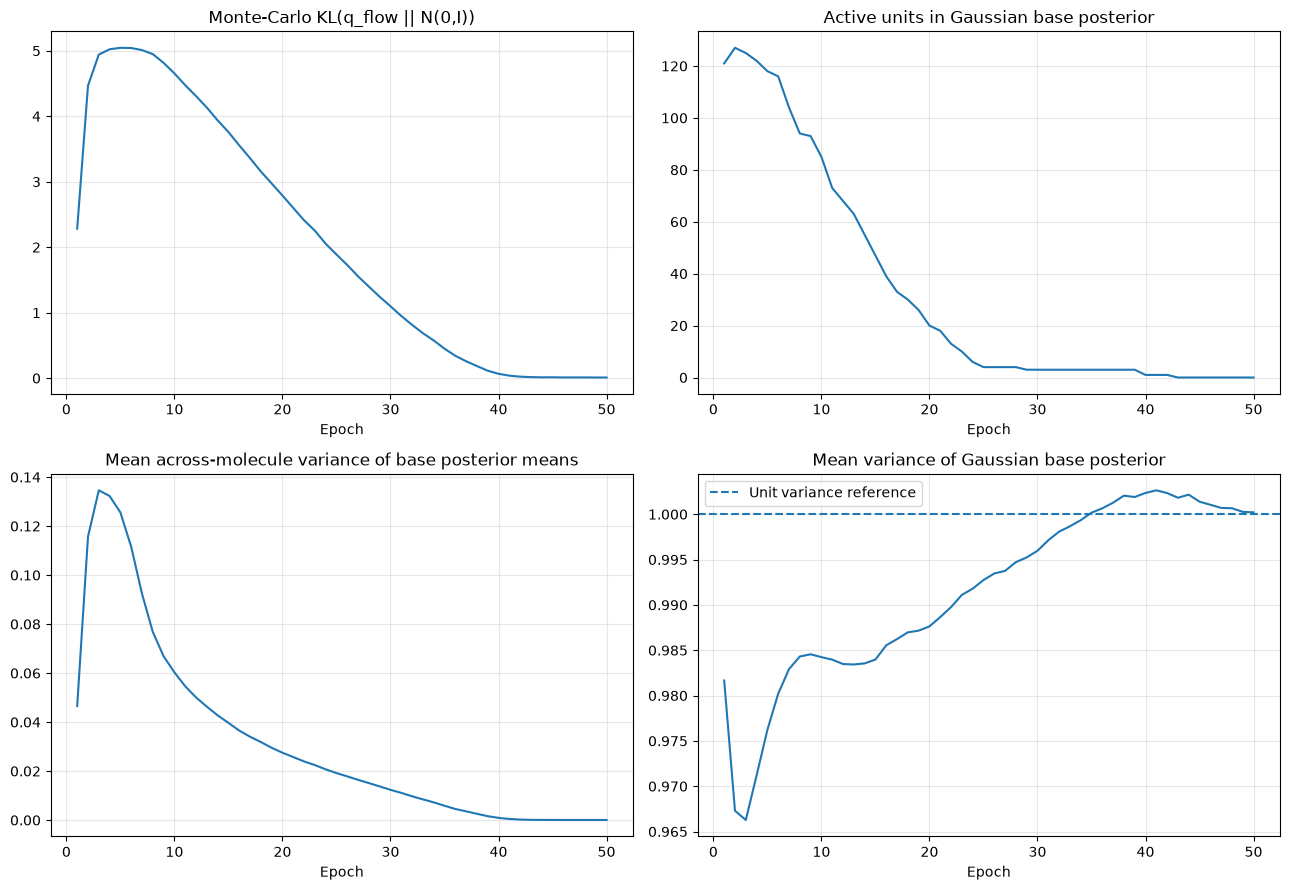

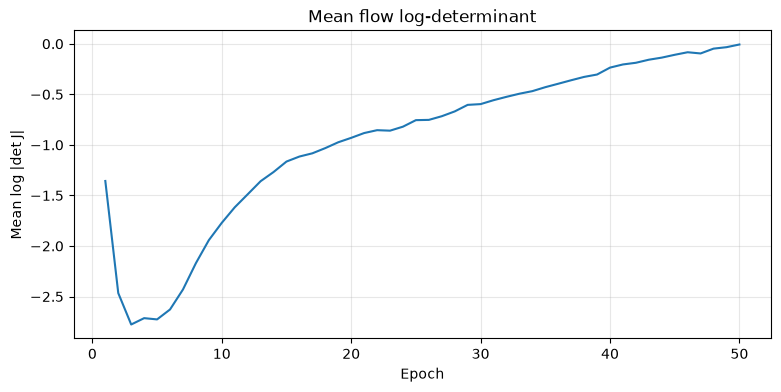

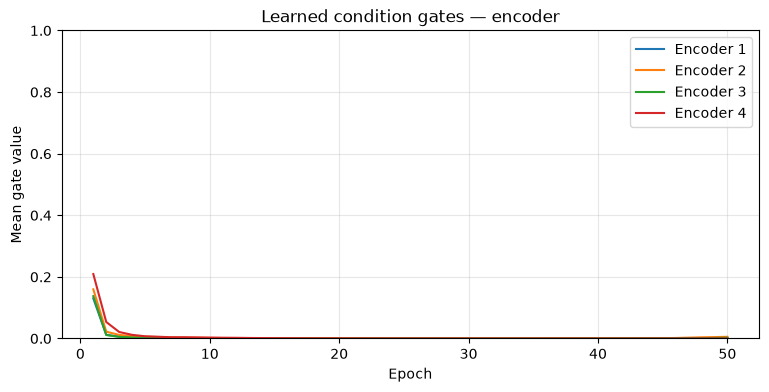

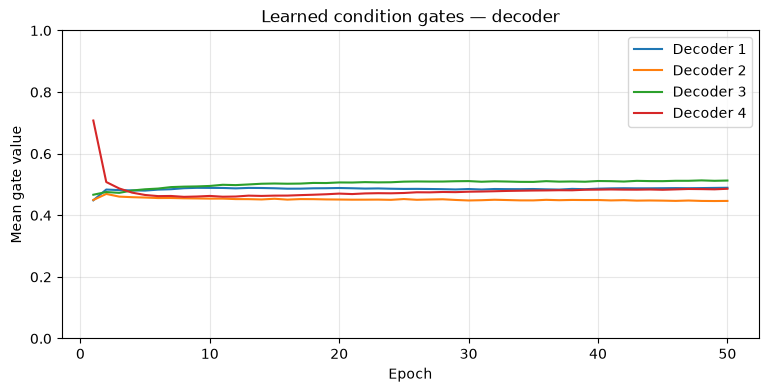

In [19]:

# Plot flow-aware training diagnostics saved in the checkpoint.
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

DIAGNOSTIC_CHECKPOINT = os.path.join(OUTPUT_DIR, "conditional_smiles_cvae.pt")
if not os.path.exists(DIAGNOSTIC_CHECKPOINT):
    raise FileNotFoundError("Run the training cell first: " + DIAGNOSTIC_CHECKPOINT)

diag_ckpt = torch.load(DIAGNOSTIC_CHECKPOINT, map_location="cpu", weights_only=False)
diag = diag_ckpt.get("training_diagnostics")
if not diag:
    raise RuntimeError("This checkpoint has no diagnostic history. Train with this notebook.")

epochs_axis = np.arange(1, len(diag["kl"]) + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(epochs_axis, diag["kl"])
axes[0, 0].set_title("Monte-Carlo KL(q_flow || N(0,I))")
axes[0, 0].set_xlabel("Epoch")

axes[0, 1].plot(epochs_axis, diag["base_active_units"])
axes[0, 1].set_title("Active units in Gaussian base posterior")
axes[0, 1].set_xlabel("Epoch")

axes[1, 0].plot(epochs_axis, diag["base_mean_variance"])
axes[1, 0].set_title("Mean across-molecule variance of base posterior means")
axes[1, 0].set_xlabel("Epoch")

axes[1, 1].plot(epochs_axis, diag["base_posterior_variance"])
axes[1, 1].axhline(1.0, linestyle="--", label="Unit variance reference")
axes[1, 1].set_title("Mean variance of Gaussian base posterior")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(epochs_axis, diag["mean_log_det"])
plt.xlabel("Epoch")
plt.ylabel("Mean log |det J|")
plt.title("Mean flow log-determinant")
plt.grid(alpha=0.3)
plt.show()

enc_gate_history = np.asarray(diag["encoder_gate_means"])
dec_gate_history = np.asarray(diag["decoder_gate_means"])
plt.figure(figsize=(9, 4))
for layer_idx in range(enc_gate_history.shape[1]):
    plt.plot(epochs_axis, enc_gate_history[:, layer_idx], label=f"Encoder {layer_idx+1}")
plt.xlabel("Epoch")
plt.ylabel("Mean gate value")
plt.ylim(0, 1)
plt.title("Learned condition gates — encoder")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(9, 4))
for layer_idx in range(dec_gate_history.shape[1]):
    plt.plot(epochs_axis, dec_gate_history[:, layer_idx], label=f"Decoder {layer_idx+1}")
plt.xlabel("Epoch")
plt.ylabel("Mean gate value")
plt.ylim(0, 1)
plt.title("Learned condition gates — decoder")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Latent sensitivity diagnostic

This test holds the condition and decoder prefix fixed and changes only the latent vector. It compares decoder token probabilities. A very small difference can indicate that the decoder is weakly sensitive to the latent variable for the tested examples; compare values across epochs and model variants rather than applying a universal threshold.

In [20]:
# Use a batch from the training data and compare two different latent samples.
probe_device = torch.device("cuda" if torch.cuda.is_available() and not FORCE_CPU else "cpu")
probe_vocab = SmilesVocabulary(qm9_df["smiles"].tolist())
probe_dataset = ConditionalSmilesDataset(qm9_df, probe_vocab, MAX_LENGTH)
probe_loader = DataLoader(
    probe_dataset, batch_size=min(32, BATCH_SIZE), shuffle=False,
    collate_fn=lambda batch: collate_batch(batch, probe_vocab.pad_id)
)
probe_x, probe_properties = next(iter(probe_loader))
probe_x = probe_x.to(probe_device)
probe_properties = probe_properties.to(probe_device)

probe_model = ConditionalTransformerCVAE(
    vocab_size=len(probe_vocab), pad_id=probe_vocab.pad_id,
    property_dim=3, d_model=D_MODEL, n_heads=N_HEADS, d_ff=D_FF,
    encoder_layers=ENCODER_LAYERS, decoder_layers=DECODER_LAYERS,
    latent_dim=LATENT_DIM, max_length=MAX_LENGTH, dropout=DROPOUT,
    flow_layers=FLOW_LAYERS
).to(probe_device)
probe_model.load_state_dict(diag_ckpt["model_state_dict"])
probe_model.eval()

with torch.no_grad():
    h_c_probe = probe_model.condition_encoder(probe_properties)
    z_a = torch.randn(probe_x.size(0), LATENT_DIM, device=probe_device)
    z_b = torch.randn_like(z_a)
    decoder_prefix = probe_x[:, :-1]
    logits_a = probe_model.decoder(decoder_prefix, h_c_probe, z_a)
    logits_b = probe_model.decoder(decoder_prefix, h_c_probe, z_b)
    prob_a = torch.softmax(logits_a, dim=-1)
    prob_b = torch.softmax(logits_b, dim=-1)

print("Mean absolute logit difference:", (logits_a - logits_b).abs().mean().item())
print("Mean absolute probability difference:", (prob_a - prob_b).abs().mean().item())

Mean absolute logit difference: 0.10422501713037491
Mean absolute probability difference: 0.0006167471292428672


## Inference analysis: PCA of base-posterior means

This PCA visualizes the Gaussian base posterior means (`mu`) before the RealNVP transformations. It is useful for inspecting the encoder representation, but it is **not** a PCA of the final flow-transformed posterior samples.


U=H=G=-50: extracted 100 posterior means; nearest standardized distance = 0.086, farthest selected = 0.131
U=H=G=-200: extracted 100 posterior means; nearest standardized distance = 0.006, farthest selected = 0.049
U=H=G=-400: extracted 100 posterior means; nearest standardized distance = 0.004, farthest selected = 0.005


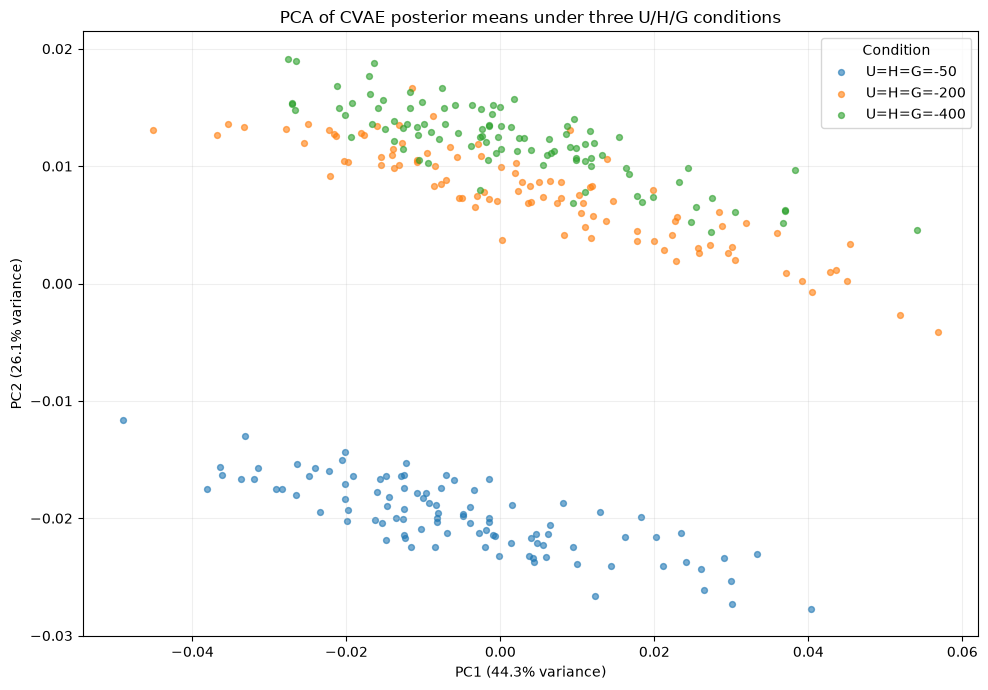

Saved PCA coordinates to: C:\Users\ch19095\Documents\outputs\posterior_mean_pca_three_conditions.csv
Explained variance by PC1+PC2: 70.43%


In [21]:
# ---- Inference-only PCA of posterior means (no training) ----
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "conditional_smiles_cvae.pt")
N_MOLECULES_PER_CONDITION = 100  # nearest dataset molecules for each target
PCA_BATCH_SIZE = 128
TARGET_CONDITIONS = {
    "U=H=G=-50":  (-200.0, -200.0, -200.0),
    "U=H=G=-200": (-300.0, -300.0, -300.0),
    "U=H=G=-400": (-400.0, -400.0, -400.0),
}

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}. Run the training cell first."
    )

# Load the trained model and its exact vocabulary/property scaling.
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
ckpt_cfg = checkpoint["config"]
ckpt_vocab = SmilesVocabulary([])
ckpt_vocab.itos = list(checkpoint["vocab"])
ckpt_vocab.stoi = {tok: i for i, tok in enumerate(ckpt_vocab.itos)}
ckpt_vocab.pad_id = ckpt_vocab.stoi[PAD]
ckpt_vocab.bos_id = ckpt_vocab.stoi[BOS]
ckpt_vocab.eos_id = ckpt_vocab.stoi[EOS]
ckpt_vocab.unk_id = ckpt_vocab.stoi[UNK]

pca_model = ConditionalTransformerCVAE(
    vocab_size=len(ckpt_vocab), pad_id=ckpt_vocab.pad_id,
    property_dim=3, d_model=ckpt_cfg["d_model"],
    n_heads=ckpt_cfg["heads"], d_ff=ckpt_cfg["d_ff"],
    encoder_layers=ckpt_cfg["encoder_layers"],
    decoder_layers=ckpt_cfg["decoder_layers"],
    latent_dim=ckpt_cfg["latent_dim"],
    max_length=ckpt_cfg["max_length"], dropout=ckpt_cfg["dropout"],
    flow_layers=ckpt_cfg.get("flow_layers", 4)
)
pca_model.load_state_dict(checkpoint["model_state_dict"])
pca_device = torch.device("cuda" if torch.cuda.is_available() and not FORCE_CPU else "cpu")
pca_model = pca_model.to(pca_device).eval()

# Load molecules and use the scaler saved during training.
pca_df = load_qm9_csv(OUTPUT_CSV)
prop_mean = np.asarray(checkpoint["property_mean"], dtype=np.float32)
prop_std = np.asarray(checkpoint["property_std"], dtype=np.float32)
prop_std = np.where(prop_std < 1e-8, 1.0, prop_std)
dataset_props = pca_df[["U", "H", "G"]].to_numpy(dtype=np.float32)
dataset_props_scaled = (dataset_props - prop_mean) / prop_std

all_mu = []
all_labels = []
all_rows = []

@torch.no_grad()
def posterior_means_for_group(smiles_values, raw_condition):
    # Feed the requested condition to the encoder for every selected molecule.
    target_scaled = (np.asarray(raw_condition, dtype=np.float32) - prop_mean) / prop_std
    means = []
    for start in range(0, len(smiles_values), PCA_BATCH_SIZE):
        batch_smiles = smiles_values[start:start + PCA_BATCH_SIZE]
        encoded = [ckpt_vocab.encode(s, ckpt_cfg["max_length"]) for s in batch_smiles]
        max_len = max(len(seq) for seq in encoded)
        x = torch.full((len(encoded), max_len), ckpt_vocab.pad_id,
                       dtype=torch.long, device=pca_device)
        for j, seq in enumerate(encoded):
            x[j, :len(seq)] = torch.tensor(seq, dtype=torch.long, device=pca_device)
        cond = torch.tensor(np.repeat(target_scaled[None, :], len(encoded), axis=0),
                            dtype=torch.float32, device=pca_device)
        h_c = pca_model.condition_encoder(cond)
        mu, _ = pca_model.encode(x, h_c)
        # Deterministic representative: transform the base posterior mean through the flow.
        zK, _ = pca_model.posterior_flow(mu, h_c)
        means.append(zK.cpu().numpy())
    return np.concatenate(means, axis=0)

for label, target in TARGET_CONDITIONS.items():
    target_scaled = (np.asarray(target, dtype=np.float32) - prop_mean) / prop_std
    distances = np.linalg.norm(dataset_props_scaled - target_scaled[None, :], axis=1)
    n_select = min(N_MOLECULES_PER_CONDITION, len(pca_df))
    nearest_idx = np.argsort(distances)[:n_select]
    selected_smiles = pca_df.iloc[nearest_idx]["smiles"].astype(str).tolist()

    group_mu = posterior_means_for_group(selected_smiles, target)
    all_mu.append(group_mu)
    all_labels.extend([label] * len(group_mu))
    all_rows.extend([
        {"condition": label, "smiles": smi,
         "nearest_condition_distance_standardized": float(distances[idx])}
        for smi, idx in zip(selected_smiles, nearest_idx)
    ])
    print(f"{label}: extracted {len(group_mu)} posterior means; "
          f"nearest standardized distance = {distances[nearest_idx[0]]:.3f}, "
          f"farthest selected = {distances[nearest_idx[-1]]:.3f}")

latent_matrix = np.vstack(all_mu)
labels = np.asarray(all_labels)
pca = PCA(n_components=2, random_state=42)
latent_2d = pca.fit_transform(latent_matrix)

plt.figure(figsize=(10, 7))
for label in TARGET_CONDITIONS:
    mask = labels == label
    plt.scatter(latent_2d[mask, 0], latent_2d[mask, 1],
                alpha=0.60, s=18, label=label)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA of CVAE posterior means under three U/H/G conditions")
plt.legend(title="Condition", frameon=True)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Save coordinates and metadata for further analysis.
pca_results = pd.DataFrame(latent_2d, columns=["PC1", "PC2"])
pca_results["condition"] = labels
pca_results["smiles"] = [row["smiles"] for row in all_rows]
pca_results["nearest_condition_distance_standardized"] = [
    row["nearest_condition_distance_standardized"] for row in all_rows
]
os.makedirs(OUTPUT_DIR, exist_ok=True)
pca_csv_path = os.path.join(OUTPUT_DIR, "posterior_mean_pca_three_conditions.csv")
pca_results.to_csv(pca_csv_path, index=False)
print("Saved PCA coordinates to:", os.path.abspath(pca_csv_path))
print("Explained variance by PC1+PC2: "
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")

In [22]:
import os
import pandas as pd
from rdkit import Chem

# Input and output files
input_csv = "outputs/generated_smiles.csv"
output_csv = "outputs/generated_smiles_validity.csv"

# Load generated SMILES
df = pd.read_csv(input_csv)

if "smiles" not in df.columns:
    raise ValueError("The input CSV must contain a 'smiles' column.")

def check_smiles(smiles):
    """Check whether a SMILES string can be parsed and sanitized by RDKit."""
    if not isinstance(smiles, str) or not smiles.strip():
        return False, None

    try:
        mol = Chem.MolFromSmiles(smiles, sanitize=True)

        if mol is None:
            return False, None

        canonical_smiles = Chem.MolToSmiles(
            mol, canonical=True
        )
        return True, canonical_smiles

    except Exception:
        return False, None

# Validate each generated molecule
results = df["smiles"].apply(check_smiles)

df["is_valid"] = results.apply(lambda result: result[0])
df["canonical_smiles"] = results.apply(lambda result: result[1])

# Calculate metrics
total = len(df)
valid_count = int(df["is_valid"].sum())
invalid_count = total - valid_count

validity_rate = (
    100 * valid_count / total if total > 0 else 0.0
)

# Uniqueness among valid molecules, using canonical SMILES
valid_smiles = df.loc[df["is_valid"], "canonical_smiles"]
unique_count = valid_smiles.nunique()
uniqueness_rate = (
    100 * unique_count / valid_count if valid_count > 0 else 0.0
)

# Save results
os.makedirs(os.path.dirname(output_csv), exist_ok=True)
df.to_csv(output_csv, index=False)

print("========== CHEMICAL VALIDITY RESULTS ==========")
print(f"Total generated molecules: {total}")
print(f"Valid molecules:           {valid_count}")
print(f"Invalid molecules:         {invalid_count}")
print(f"Validity rate:             {validity_rate:.2f}%")
print(f"Unique valid molecules:    {unique_count}")
print(f"Uniqueness among valid:    {uniqueness_rate:.2f}%")
print(f"\nResults saved to: {os.path.abspath(output_csv)}")

# Display a sample of results
display(df.head(10))

========== CHEMICAL VALIDITY RESULTS ==========
Total generated molecules: 2000
Valid molecules:           1657
Invalid molecules:         343
Validity rate:             82.85%
Unique valid molecules:    380
Uniqueness among valid:    22.93%

Results saved to: C:\Users\ch19095\Documents\outputs\generated_smiles_validity.csv


,smiles,is_valid,canonical_smiles
0,C[C@@H]1C[C@H]2C[C@H]2[C@H]2C[C@H]21,True,C[C@@H]1C[C@H]2C[C@H]2[C@H]2C[C@H]21
1,C1=NCC[C@@H]2C[C@H](O)[C@H]12,True,O[C@H]1C[C@H]2CCN=C[C@H]21
2,C[C@@H]1C,False,NaN
3,C#CC,True,C#CC
4,C[C@@H]1C[C@H]2C=C[C@H]2[C@H]1O,True,C[C@@H]1C[C@H]2C=C[C@H]2[C@H]1O
5,C[C@@H]1C[C@H]2C[C@H]2C[C@H]2O1,False,NaN
6,C#C[C@@H]1CC[C@H]2C[C@H]2C1,True,C#C[C@@H]1CC[C@H]2C[C@H]2C1
7,C[C@@H]1C[C@H]2C[C@H]2C[C@H]1O,True,C[C@@H]1C[C@H]2C[C@H]2C[C@H]1O
8,C[C@@H]1[C@H]2CC[C@H]2[C@H]2C[C@H]21,True,C[C@@H]1[C@H]2CC[C@H]2[C@H]2C[C@@H]12
9,C#C[C@@H]1C[C@H]2C[C@H]2[C@H]1O,True,C#C[C@@H]1C[C@H]2C[C@H]2[C@H]1O


## Notes and recommended first experiment

- The checkpoint is saved to `outputs/conditional_smiles_cvae.pt`.
- The default flow has **4 conditional RealNVP coupling layers** and latent dimension 128.
- The flow is initialized close to identity, which helps stabilize the transition from the baseline.
- Generation samples the final latent variable directly from the standard-normal prior. The posterior flow is not applied to prior samples.
- The KL term is a Monte-Carlo estimate and includes the flow log-determinant correction.
- Base-posterior active-unit diagnostics should not be interpreted as exact active-unit counts for the transformed posterior.
- Compare this model with the original CVAE using the same data, seed, training duration, and decoding settings. A flow is not guaranteed to increase uniqueness or prevent posterior collapse.


## Inference-only decoder generation from flow-transformed base posterior means

The PCA/generation cells use `zK = flow(mu, h_c)`, i.e. the deterministic flow transform of the base Gaussian mean. This is a representative latent code, not the exact mean of the transformed posterior distribution.


In [23]:
# ---- Inference-only decoder generation using flow-transformed base posterior means ----
# This cell uses group_mu computed in the PCA cell above as zK = flow(mu, h_c).
# It does NOT sample a new z from N(0,I), and it does NOT train/update the model.
# Each source molecule's posterior mean is paired with the corresponding target condition.

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

GEN_BATCH_SIZE = 64
GEN_TEMPERATURE = 0.8
GEN_MAX_LENGTH = int(ckpt_cfg["max_length"])

@torch.no_grad()
def decode_from_posterior_means(model, z_means, raw_condition, vocab,
                                batch_size=64, max_length=128, temperature=0.8):
    """Autoregressively decode supplied posterior means with one target condition."""
    model.eval()
    target_scaled = (np.asarray(raw_condition, dtype=np.float32) - prop_mean) / prop_std
    all_smiles = []

    for start in range(0, len(z_means), batch_size):
        z = torch.as_tensor(z_means[start:start + batch_size],
                            dtype=torch.float32, device=pca_device)
        batch_n = z.size(0)
        cond = torch.tensor(np.repeat(target_scaled[None, :], batch_n, axis=0),
                            dtype=torch.float32, device=pca_device)
        h_c = model.condition_encoder(cond)

        generated = torch.full((batch_n, 1), vocab.bos_id,
                               dtype=torch.long, device=pca_device)
        finished = torch.zeros(batch_n, dtype=torch.bool, device=pca_device)

        for _ in range(max_length - 1):
            logits = model.decoder(generated, h_c, z)
            next_logits = logits[:, -1, :] / max(float(temperature), 1e-5)
            next_logits[:, vocab.pad_id] = -float("inf")
            next_logits[:, vocab.bos_id] = -float("inf")
            next_token = torch.multinomial(F.softmax(next_logits, dim=-1), 1)
            next_token = torch.where(
                finished.unsqueeze(1),
                torch.full_like(next_token, vocab.pad_id), next_token
            )
            generated = torch.cat([generated, next_token], dim=1)
            finished |= next_token.squeeze(1).eq(vocab.eos_id)
            if finished.all():
                break

        all_smiles.extend(vocab.decode(row.tolist()) for row in generated)

    return all_smiles

# `all_mu` and `all_rows` were created by the PCA cell. Keep their ordering aligned.
combined_generated = []
os.makedirs(OUTPUT_DIR, exist_ok=True)

for group_index, (condition_label, target) in enumerate(TARGET_CONDITIONS.items()):
    posterior_mu_group = all_mu[group_index]
    source_rows_group = all_rows[
        group_index * len(posterior_mu_group):(group_index + 1) * len(posterior_mu_group)
    ]
    source_smiles_group = [row["smiles"] for row in source_rows_group]

    generated_smiles = decode_from_posterior_means(
        pca_model, posterior_mu_group, target, ckpt_vocab,
        batch_size=GEN_BATCH_SIZE,
        max_length=GEN_MAX_LENGTH,
        temperature=GEN_TEMPERATURE
    )

    group_df = pd.DataFrame({
        "condition": condition_label,
        "target_U": target[0],
        "target_H": target[1],
        "target_G": target[2],
        "source_smiles": source_smiles_group,
        "posterior_mean_generated_smiles": generated_smiles,
    })
    safe_label = condition_label.replace("=", "_").replace("-", "minus")
    group_path = os.path.join(OUTPUT_DIR, f"posterior_mean_decoded_{safe_label}.csv")
    group_df.to_csv(group_path, index=False)
    combined_generated.append(group_df)
    print(f"{condition_label}: decoded {len(generated_smiles)} SMILES")
    print("Saved:", os.path.abspath(group_path))

combined_path = os.path.join(OUTPUT_DIR, "posterior_mean_decoded_all_three_conditions.csv")
pd.concat(combined_generated, ignore_index=True).to_csv(combined_path, index=False)
print("\nCombined file saved:", os.path.abspath(combined_path))
print("These outputs were decoded from flow-transformed base posterior means (zK = flow(mu, h_c)), not from prior samples.")


U=H=G=-50: decoded 100 SMILES
Saved: C:\Users\ch19095\Documents\outputs\posterior_mean_decoded_U_H_G_minus50.csv
U=H=G=-200: decoded 100 SMILES
Saved: C:\Users\ch19095\Documents\outputs\posterior_mean_decoded_U_H_G_minus200.csv
U=H=G=-400: decoded 100 SMILES
Saved: C:\Users\ch19095\Documents\outputs\posterior_mean_decoded_U_H_G_minus400.csv

Combined file saved: C:\Users\ch19095\Documents\outputs\posterior_mean_decoded_all_three_conditions.csv
These outputs were decoded from flow-transformed base posterior means (zK = flow(mu, h_c)), not from prior samples.
